# Run modes

Pysummada configs now use `run_mode` to select deterministic, DA, and ESP combinations. Snow5 workflows keep their own YAML structure with optional `esp` settings under the Snow5 DA config.


## Run initial Snow 5 model model tests ##

In [ ]:
from pathlib import Path
# add auto reload for jupyter magic
%load_ext autoreload
%autoreload 2

In [ ]:
# Option A: Run a single snow5 simulation
from snowda.workflows.run_snow5 import run_snow5

config_path = Path("../runs/examples/chena_snow5.yaml").resolve()
run_dir_open_loop = run_snow5(config_path)
print("snow5 run dir:", run_dir_open_loop)

In [ ]:
from pathlib import Path

import xarray as xr
from snowda.utils.logging import configure_logging
from snowda.viz import plot_snow5_timeseries
from snowda.workflows.run_snow5 import run_snow5

config_path = Path("../runs/examples/chena_snow5.yaml")

configure_logging(level="INFO")

# Run the workflow (optional if you already have existing outputs)
run_dir = run_snow5(config_path)

# Open the output that now contains both forcing and SWE
result_path = run_dir / "snow5_output.nc"
result_ds = xr.open_dataset(result_path)

# Plot HRU 0 directly from the output dataset
fig = plot_snow5_timeseries(result_ds, result_ds, hru=100)
fig.show()

In [ ]:
from pathlib import Path

import xarray as xr
from snowda.utils.logging import configure_logging
from snowda.viz import plot_snow5_timeseries
from snowda.workflows.run_snow5 import run_snow5

config_path = Path("../runs/examples/chena_snow5.yaml")
configure_logging(level="INFO")

run_dir = run_snow5(config_path)

output_path = run_dir / "snow5_output.nc"
ds = xr.open_dataset(output_path)

fig = plot_snow5_timeseries(ds, ds, hru=0)
fig.show()

In [37]:
from pathlib import Path

from snowda.workflows.run_snow5_da import run_snow5_da

config_path = Path("../runs/examples/chena_snow5_da.yaml")
run_dir = run_snow5_da(config_path)
print(f"Snow5 DA run complete. Outputs and provenance under {run_dir}")

2026-01-23 09:15:43 | INFO     | snowda.snowda.io.snow5 | Reading snow5 forcing from /Users/dcasson/Data/snowda/summa/chena/forcing/rf_best_regression_static_dynamic_ensMember_001.nc
2026-01-23 09:15:45 | INFO     | snowda.snowda.workflows.run_snow5 | Using uniform CV=0.7 for 329 HRUs
2026-01-23 09:15:45 | INFO     | snowda.snowda.io.snow5 | Reading snow5 forcing from /Users/dcasson/Data/snowda/summa/chena/forcing/rf_best_regression_static_dynamic_ensMember_001.nc
2026-01-23 09:15:46 | INFO     | snowda.snowda.io.snow5 | Reading snow5 forcing from /Users/dcasson/Data/snowda/summa/chena/forcing/rf_best_regression_static_dynamic_ensMember_002.nc
2026-01-23 09:15:47 | INFO     | snowda.snowda.io.snow5 | Reading snow5 forcing from /Users/dcasson/Data/snowda/summa/chena/forcing/rf_best_regression_static_dynamic_ensMember_003.nc
2026-01-23 09:15:49 | INFO     | snowda.snowda.io.snow5 | Reading snow5 forcing from /Users/dcasson/Data/snowda/summa/chena/forcing/rf_best_regression_static_dynamic

Snow5 DA run complete. Outputs and provenance under /Users/dcasson/GitHub/snowda/outputs/chena_snow5_da/20260123T161543Z


/var/folders/46/6y3tkg051374dmsgd2w6l9gw0000gn/T/ipykernel_33870/3318293817.py:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


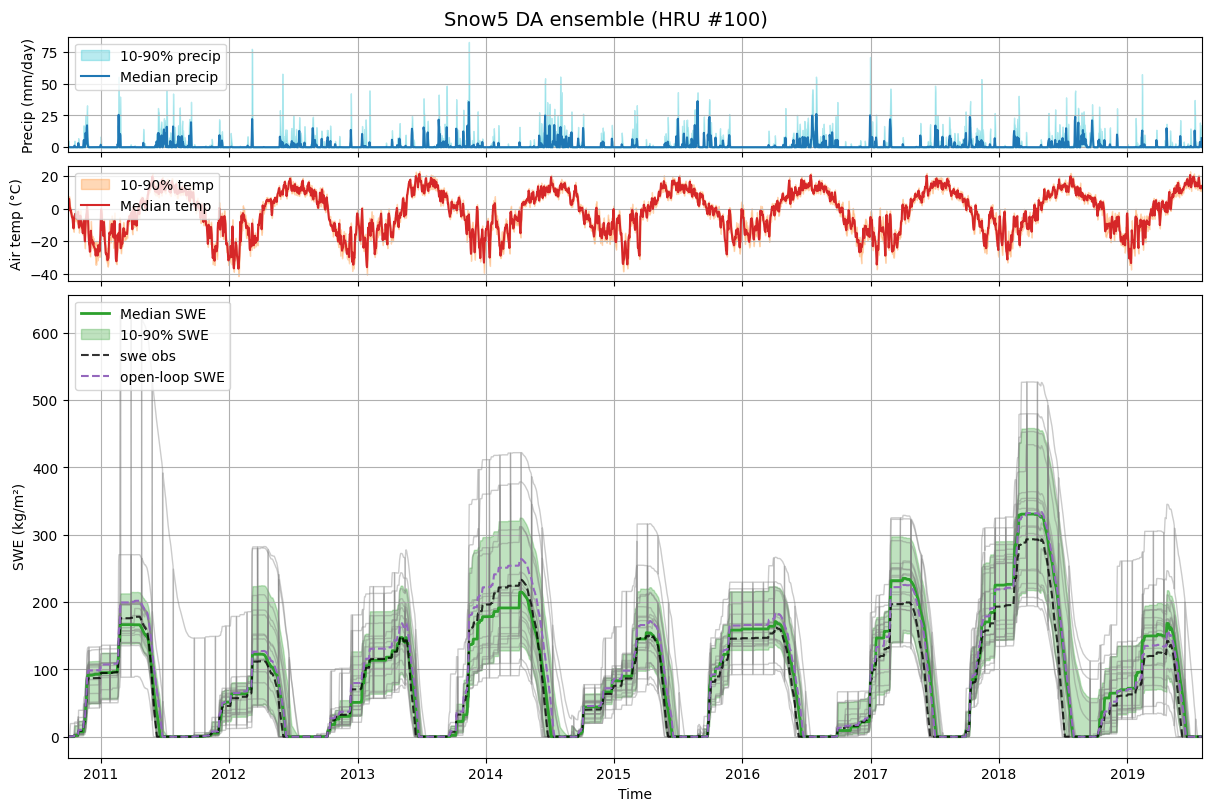

In [39]:
import xarray as xr
from pathlib import Path
from snowda.viz import plot_snow5_da
#run_dir = Path("/Users/dcasson/GitHub/snowda/outputs/chena_snow5_da/20260121T224101Z")
datasets = [xr.open_dataset(p) for p in sorted(run_dir.glob("*_snow5_output.nc"))]
obs_ds = xr.open_dataset("/Users/dcasson/Data/snowda/summa/chena/observations/test_observations.nc")
open_loop_ds = xr.open_dataset(run_dir_open_loop / "snow5_output.nc")
fig = plot_snow5_da(
    datasets,
    hru=100,
    obs_da=obs_ds["swe"],
    obs_var_name="swe",
    open_loop_ds=open_loop_ds,
)
fig.show()

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import xarray as xr

def plot_forcing_samples(
    forcing_dir: Path,
    pattern: str = "*.nc",
    sample_limit: int = 5,
    hru_index: int = 0,
):
    """Plot precip + temperature traces for a few forcing members."""
    files = sorted(forcing_dir.glob(pattern))
    if not files:
        raise FileNotFoundError(f"No files matching {pattern} in {forcing_dir}")
    files = files[:sample_limit]

    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, constrained_layout=True)
    ax_precip, ax_temp = axes

    for f in files:
        ds = xr.open_dataset(f)
        times = ds["time"].values
        precip = ds["pptrate"].isel(hru=hru_index).values * 3600.0  # convert to mm/day
        temp = ds["airtemp"].isel(hru=hru_index).values - 273.15
        label = f.name
        ax_precip.plot(times, precip, alpha=0.6, label=label)
        ax_temp.plot(times, temp, alpha=0.6, label=label)
        ds.close()

    ax_precip.set_title(f"Sampled forcing precip (HRU {hru_index})")
    ax_precip.set_ylabel("Precip (mm/day)")
    ax_precip.legend(fontsize="x-small")

    ax_temp.set_title("Sampled forcing air temperature")
    ax_temp.set_ylabel("Temperature (°C)")
    ax_temp.set_xlabel("Time")
    ax_temp.legend(fontsize="x-small")

    plt.show()

# Example usage:
plot_forcing_samples(
    Path("/Users/dcasson/Data/snowda/summa/chena/forcing/"),
    pattern="*.nc",
    sample_limit=4,
    hru_index=0,
)